# FashionMNIST classification

Two image classifiers trained on [FashionMNIST](https://github.com/zalandoresearch/fashion-mnist) with PyTorch: a fully connected baseline and a small convolutional network. Both are evaluated on the 10,000 test images they never see during training.

In [1]:
from timeit import default_timer as timer

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
device

'mps'

## Data

70,000 greyscale 28×28 images of clothing in 10 categories: 60,000 for training, 10,000 for testing.

In [2]:
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=ToTensor())

class_names = train_data.classes
len(train_data), len(test_data), class_names

(60000,
 10000,
 ['T-shirt/top',
  'Trouser',
  'Pullover',
  'Dress',
  'Coat',
  'Sandal',
  'Shirt',
  'Sneaker',
  'Bag',
  'Ankle boot'])

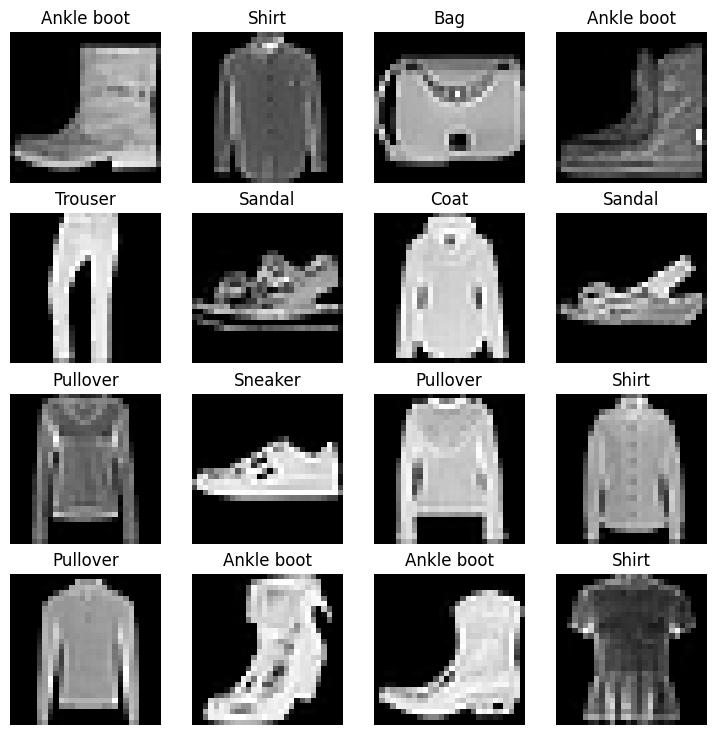

In [3]:
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4

for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

In [4]:
BATCH_SIZE = 64

train_data_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_data_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

len(train_data_loader), len(test_data_loader)

(938, 157)

## Training and evaluation

Each epoch trains on the whole training set, then measures loss and accuracy on the test set.

In [5]:
def train_step(model, data_loader, loss_fn, optimizer):
    model.train()
    total_loss, correct = 0.0, 0
    for X, y in data_loader:
        X, y = X.to(device), y.to(device)

        y_logits = model(X)
        loss = loss_fn(y_logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (y_logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(data_loader), correct / len(data_loader.dataset) * 100


def test_step(model, data_loader, loss_fn):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            y_logits = model(X)
            total_loss += loss_fn(y_logits, y).item()
            correct += (y_logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(data_loader), correct / len(data_loader.dataset) * 100


def train(model, epochs, lr=0.1, print_every=1):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    history = {"train_acc": [], "test_acc": []}
    start = timer()
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_step(model, train_data_loader, loss_fn, optimizer)
        test_loss, test_acc = test_step(model, test_data_loader, loss_fn)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        if epoch % print_every == 0 or epoch == 1:
            print(f"Epoch {epoch:3d} | train loss {train_loss:.4f}, acc {train_acc:.2f}% "
                  f"| test loss {test_loss:.4f}, acc {test_acc:.2f}%")
    training_time = timer() - start
    print(f"Training time on {device}: {training_time:.0f} s")

    return {"train_acc": train_acc, "test_loss": test_loss, "test_acc": test_acc,
            "training_time": training_time, "history": history}

## Model 0: fully connected baseline

The image is flattened into 784 values and passed through two hidden layers of 10 units.

In [6]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_shape, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, output_shape),
        )

    def forward(self, x):
        return self.layer_stack(x)


torch.manual_seed(42)
model_0 = FashionMNISTModelV0(input_shape=28 * 28, hidden_units=10, output_shape=len(class_names)).to(device)
results_0 = train(model_0, epochs=3)

Epoch   1 | train loss 0.7701, acc 72.23% | test loss 0.5912, acc 79.25%


Epoch   2 | train loss 0.5222, acc 81.20% | test loss 0.5025, acc 81.62%


Epoch   3 | train loss 0.4700, acc 83.10% | test loss 0.5081, acc 81.54%
Training time on mps: 7 s


## Model 1: convolutional network

Two convolutional blocks (two 3×3 convolutions and a max pooling each) extract visual features, then a linear layer classifies them.

In [7]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(input_shape, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # Two max poolings: 28x28 -> 14x14 -> 7x7
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(hidden_units * 7 * 7, output_shape),
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        return self.classifier(x)


torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=1, hidden_units=10, output_shape=len(class_names)).to(device)
results_1 = train(model_1, epochs=100, print_every=10)

Epoch   1 | train loss 0.7221, acc 74.01% | test loss 0.4376, acc 84.13%


Epoch  10 | train loss 0.2597, acc 90.51% | test loss 0.2870, acc 89.69%


Epoch  20 | train loss 0.2196, acc 92.03% | test loss 0.2796, acc 89.67%


Epoch  30 | train loss 0.2036, acc 92.64% | test loss 0.2737, acc 90.28%


Epoch  40 | train loss 0.1934, acc 93.05% | test loss 0.2691, acc 90.75%


Epoch  50 | train loss 0.1833, acc 93.35% | test loss 0.2914, acc 89.40%


Epoch  60 | train loss 0.1789, acc 93.40% | test loss 0.2871, acc 90.18%


Epoch  70 | train loss 0.1740, acc 93.56% | test loss 0.2901, acc 89.96%


Epoch  80 | train loss 0.1696, acc 93.72% | test loss 0.2898, acc 90.03%


Epoch  90 | train loss 0.1651, acc 93.91% | test loss 0.2856, acc 90.29%


Epoch 100 | train loss 0.1648, acc 93.73% | test loss 0.3175, acc 89.40%
Training time on mps: 370 s


## Results

In [8]:
for name, results in [("Model 0 (fully connected)", results_0), ("Model 1 (convolutional)", results_1)]:
    print(f"{name:27s} train acc {results['train_acc']:.2f}% | test acc {results['test_acc']:.2f}% "
          f"| test loss {results['test_loss']:.4f}")

Model 0 (fully connected)   train acc 83.10% | test acc 81.54% | test loss 0.5081
Model 1 (convolutional)     train acc 93.73% | test acc 89.40% | test loss 0.3175


## Accuracy over training

Train and test accuracy of the convolutional network after each epoch.

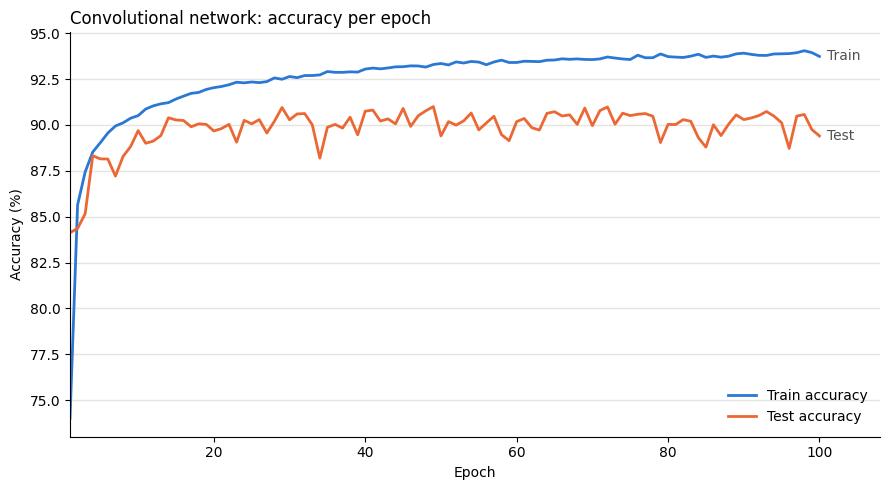

In [9]:
history = results_1["history"]
epochs = range(1, len(history["train_acc"]) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, history["train_acc"], color="#2a78d6", linewidth=2, label="Train accuracy")
ax.plot(epochs, history["test_acc"], color="#eb6834", linewidth=2, label="Test accuracy")
ax.text(epochs[-1] + 1, history["train_acc"][-1], "Train", color="#52514e", va="center")
ax.text(epochs[-1] + 1, history["test_acc"][-1], "Test", color="#52514e", va="center")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Convolutional network: accuracy per epoch", loc="left")
ax.set_xlim(1, epochs[-1] + 8)
ax.grid(axis="y", color="#e5e4e0", linewidth=1)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()

## Predictions on test images

Green: correct prediction. Red: wrong prediction (true label in brackets).

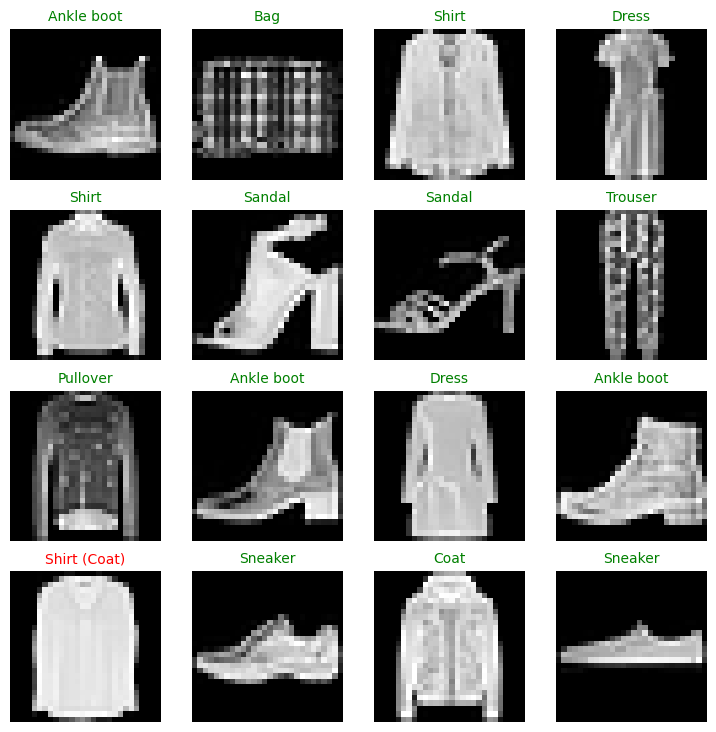

In [10]:
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4

model_1.eval()
with torch.inference_mode():
    for i in range(1, rows * cols + 1):
        random_idx = torch.randint(0, len(test_data), size=[1]).item()
        img, label = test_data[random_idx]
        pred = model_1(img.unsqueeze(dim=0).to(device)).argmax(dim=1).item()

        fig.add_subplot(rows, cols, i)
        plt.imshow(img.squeeze(), cmap="gray")
        if pred == label:
            plt.title(class_names[pred], color="green", fontsize=10)
        else:
            plt.title(f"{class_names[pred]} ({class_names[label]})", color="red", fontsize=10)
        plt.axis(False)